# Simple Linear Regression Practical (ABA Unit 1, Practical 8)

**Aim:** apply regression analysis to identify the relationship between advertising expenditure and sales revenue (Sahyadri Mart daily sales, synthetic).

Run the cells in order (Runtime → Run all). Nothing to install. The note `simple-linear-regression-practical` on Sutra explains every step.

In [1]:
# Step 1. Load the data
import pandas as pd
import numpy as np

url = ("https://raw.githubusercontent.com/Prathameshv07/ai-ds-notes/main/"
       "content/assets/data/sahyadri-mart-sales.csv")
df = pd.read_csv(url, parse_dates=["date"])
x, y = df["ad_spend_inr"], df["revenue_inr"]
print("Rows, columns:", df.shape)

Rows, columns: (8772, 16)


In [2]:
# Step 2. Least-squares line for the whole chain: revenue = a + b * ad_spend
b = ((x - x.mean()) * (y - y.mean())).sum() / ((x - x.mean())**2).sum()
a = y.mean() - b * x.mean()
r = x.corr(y)
print(f"Slope b     : {b:.2f}  (Rs of revenue per extra Rs 1 of ads)")
print(f"Intercept a : {a:,.0f}")
print(f"r = {r:.3f},  R^2 = {r**2:.3f}")

Slope b     : 72.53  (Rs of revenue per extra Rs 1 of ads)
Intercept a : 160,589
r = 0.608,  R^2 = 0.369


In [3]:
# Step 3. Check with NumPy's built-in least-squares fit
b_np, a_np = np.polyfit(x, y, 1)
print(f"np.polyfit: slope = {b_np:.2f}, intercept = {a_np:,.0f}")

np.polyfit: slope = 72.53, intercept = 160,589


In [4]:
# Step 4. Fit the same line inside each store
def fit(g):
    gx, gy = g["ad_spend_inr"], g["revenue_inr"]
    slope = gx.cov(gy) / gx.var()
    return pd.Series({"slope_b": slope, "intercept_a": gy.mean() - slope * gx.mean(),
                      "r": gx.corr(gy), "R2": gx.corr(gy)**2})
per_store = df.groupby("store_id")[["ad_spend_inr", "revenue_inr"]].apply(fit)
print(per_store.round(3).to_string())
print(f"\nMedian within-store slope: {per_store['slope_b'].median():.1f}")

          slope_b  intercept_a      r     R2
store_id                                    
S01        20.375   952726.084  0.254  0.065
S02        14.063   312514.498  0.214  0.046
S03         9.821   134842.061  0.295  0.087
S04        26.268   796402.988  0.343  0.118
S05        14.400   286411.545  0.251  0.063
S06         8.633   171324.361  0.229  0.052
S07        15.451   502708.597  0.326  0.106
S08         8.890   137898.042  0.274  0.075
S09        11.316   471223.181  0.263  0.069
S10         7.826   125764.218  0.262  0.069
S11        16.988   567350.830  0.335  0.112
S12        11.359   143629.651  0.308  0.095

Median within-store slope: 12.7


In [5]:
# Step 5. Remove store size: compare each day with its own store's average
xd = x - df.groupby("store_id")["ad_spend_inr"].transform("mean")
yd = y - df.groupby("store_id")["revenue_inr"].transform("mean")
b_within = (xd * yd).sum() / (xd**2).sum()
print(f"Chain-wide slope   : {b:.1f}")
print(f"Within-store slope : {b_within:.1f}")
print(f"Within-store r     : {xd.corr(yd):.2f}")

Chain-wide slope   : 72.5
Within-store slope : 16.9
Within-store r     : 0.29


In [6]:
# Step 6. Predict S01's revenue on a day with Rs 10,000 of ads: which line?
s01, p = df[df["store_id"] == "S01"], per_store.loc["S01"]
print(f"S01 average day : ad Rs {s01['ad_spend_inr'].mean():,.0f}, revenue Rs {s01['revenue_inr'].mean():,.0f}")
print(f"Chain-wide line : Rs {a + b * 10000:,.0f}")
print(f"S01's own line  : Rs {p['intercept_a'] + p['slope_b'] * 10000:,.0f}")

S01 average day : ad Rs 6,091, revenue Rs 1,076,818
Chain-wide line : Rs 885,875
S01's own line  : Rs 1,156,472


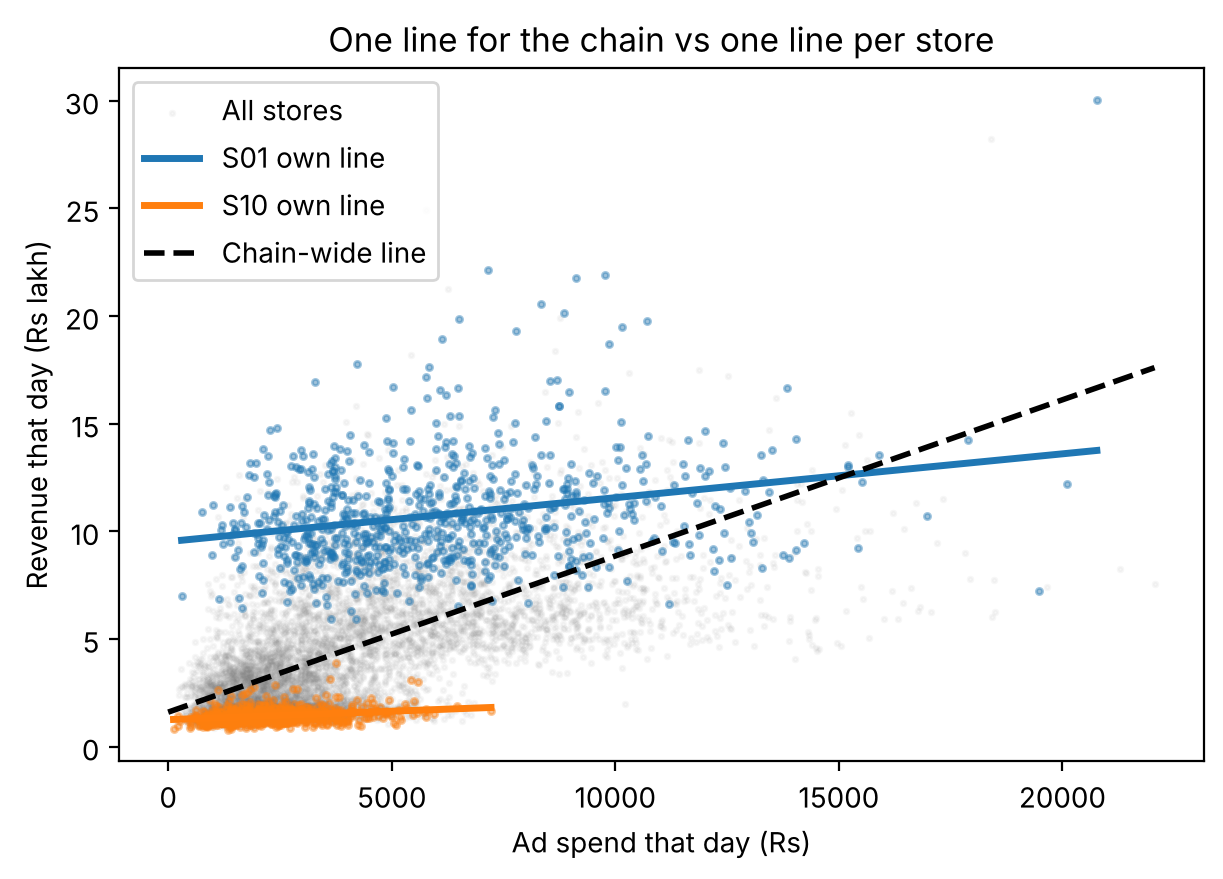

In [7]:
# Step 7. Plot the chain-wide line and two stores' own lines
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(x, y / 1e5, s=3, alpha=0.06, color="grey", label="All stores")
for sid, colour in [("S01", "tab:blue"), ("S10", "tab:orange")]:
    g, p = df[df["store_id"] == sid], per_store.loc[sid]
    xs = np.linspace(g["ad_spend_inr"].min(), g["ad_spend_inr"].max(), 50)
    ax.scatter(g["ad_spend_inr"], g["revenue_inr"] / 1e5, s=5, alpha=0.4, color=colour)
    ax.plot(xs, (p["intercept_a"] + p["slope_b"] * xs) / 1e5, color=colour, lw=2.5, label=f"{sid} own line")
xs = np.linspace(0, x.max(), 50)
ax.plot(xs, (a + b * xs) / 1e5, color="black", lw=2, ls="--", label="Chain-wide line")
ax.set_xlabel("Ad spend that day (Rs)")
ax.set_ylabel("Revenue that day (Rs lakh)")
ax.set_title("One line for the chain vs one line per store")
ax.legend()
plt.show()